# 51 Peg

This section is a hands-on tutorial on how to make a simple run.
We use the 51 Peg RV data available on [GitHub](https://github.com/ReddTea/astroemperor/tree/main/tests/datafiles/51Peg/RV).

## Data
We need to set up our working directory with two subfolders, `datafiles` and `datalogs`. 

`datafiles` will contain our RV catalogues. For each target or system we create a subfolder with the system name. In this case, `51Peg`. Inside, we create a second subfolder, named `RV`, which will contain the data to be read.

We copy-paste the file downloaded from GitHub into `/datafiles/51Peg/RV/`.


```
📂working_directory
 ┣ 📜mini_test.py
 ┣ 📂datafiles
 ┃ ┣ 📂51Peg
 ┃ ┃ ┗ 📂RV
 ┃ ┃   ┗ 📜51peg.vels
 ┣ 📂datalogs
 ┃ ┣ 📂51Peg
 ┃ ┃ ┗ 📂run_1
```

## Setting up EMPEROR

Under our working directory, we create a python file named `mini_test`.
First, we import the library and start our simulation:

In [1]:
import astroemperor as emp
import numpy as np
np.random.seed(1234)


sim = emp.Simulation()
sim.load_data('51Peg')  # folder read from /datafiles/

I couldnt grab the terminal size. Trying with pandas...
Terminal size with pandas successful!
                                                                                
                   ~~ Simulation Successfully Initialized ~~                    
                                                                                


                         
Reading data from 51peg.vels                          








### Setting the engine

For this example, we will use `reddemcee`, with 10 temperatures, 256 walkers, 2048 sweeps each of 1 step:

In [2]:
sim.set_engine('reddemcee')
sim.engine_config['setup'] = [10, 256, 2048, 1]

### Setting the model
We feed the name of the instrument (optional), as well as the starmass for calculating the minimum-mass and semi-major axis. We will use the Keplerian parameterisation ($P$, $K$, $\phi$, $e_{s}$, $e_{c}$). We add some boundaries to speed up the process, and add some initial positions:

In [3]:
sim.instrument_names_RV = ['LICK']
sim.starmass = 1.12  # in solar masses
sim.keplerian_parameterisation = 1  # see above description

# Initial Positions
sim.add_condition(['Period 1', 'limits', [3, 5]])
sim.add_condition(['Amplitude 1', 'limits', [45, 60]])

sim.add_condition(['Offset 1', 'limits', [-10., 10.]])

sim.add_condition(['Period 1', 'init_pos', [4.1, 4.3]])
sim.add_condition(['Amplitude 1', 'init_pos', [50, 60]])

### Plotting Options
We add some plotting options to speed up this test a little. We will plot the posteriors for the cold chain (0), and two intermediate chains (2, and 6). Also, we won't use the `arviz` optional plots.

In [4]:
sim.plot_posteriors['temps'] = [0, 2, 6]
sim.plot_trace['plot'] = False  # arviz plots

Finally, we run our simulation (it will take some minutes):

In [5]:
sim.autorun(0, 1)

                              Offset block added, OffsetBlock


                              Jitter block added, JitterBlock



Condition applied: Parameter Offset 1 attribute limits set to [-10.0, 10.0]


                                ~~ Setup Info ~~                                


Current Engine is            reddemcee 0.9.12
Number of cores is           24
Save location is             datalogs/51Peg/run_5/k0
Dynamical Criteria is        None
Posterior fit method is      Gaussian Mixtures
Limits constrain method is   range
Model Selection method is    BIC


                           ~~ Automatically Saving ~~                           


Logger       : ✔
Samples      : ✘
Posteriors   : ✔
Likelihoods  : ✔
Plots: Posteriors           : ✔
Plots: Keplerian Model      : ✔
Plots: Gaussian Mixture     : ✔
Plots: Parameter Histograms : ✔
Plots: Corner               : ✔


                               ~~ Pre-Run Info ~~                               


Parameter    Prior              

100%|██████████| 20480/20480 [03:25<00:00, 99.51it/s] 


temp_script.py took 206.036 seconds
Autocorrelation tolerance=50 fails. Setting to 0.


/IronCrane/reddtea/pip_packages/reddemcee/src/reddemcee/utils.py:294: RuntimeWarning: overflow encountered in exp
  C_series = np.exp(logC_series)
/IronCrane/reddtea/pip_packages/reddemcee/src/reddemcee/utils.py:54: RuntimeWarning: invalid value encountered in subtract
  bm = (csum[b:] - csum[:-b]) / b
/IronCrane/reddtea/pip_packages/reddemcee/src/reddemcee/utils.py:55: RuntimeWarning: invalid value encountered in subtract
  diff = bm - mu_hat
/IronCrane/reddtea/pip_packages/reddemcee/src/reddemcee/utils.py:56: RuntimeWarning: overflow encountered in matmul
  Sigma_hat = (b / K) * diff.T @ diff


Are you running a short chain? Evidence with hybrid failed! Trying fallback to TI+.
                         Calculating Gaussian Mixtures                          


...



                           Plotting Temperature Rates                           


100%|██████████| 9/9 [00:00<00:00,  9.75it/s]




                           Plotting Gaussian Mixtures                           


100%|██████████| 11/11 [00:02<00:00,  4.43it/s]





Time Table
Time RUN                   : 00:03:39
Time POSTPROCESS           : 00:00:15
Time CALCULATE GM          : 00:00:10
Time plot_posteriors       : 00:00:28
Time plot_histograms       : 00:00:19
Time plot_keplerian_model  : 00:00:00
Time plot_betas            : 00:00:00
Time plot_beta_density     : 00:00:00
Time plot_rates            : 00:00:00
Time plot_trace            : 00:00:00

past BIC - present BIC > 5

 BIC condition met!!
2628.671 - 1777.974 > 5


                                                                                
                              ~~ End of the Run ~~                              
                                                                                




Now we can explore the results in the `/datalogs/51Peg/run_1/` folder:

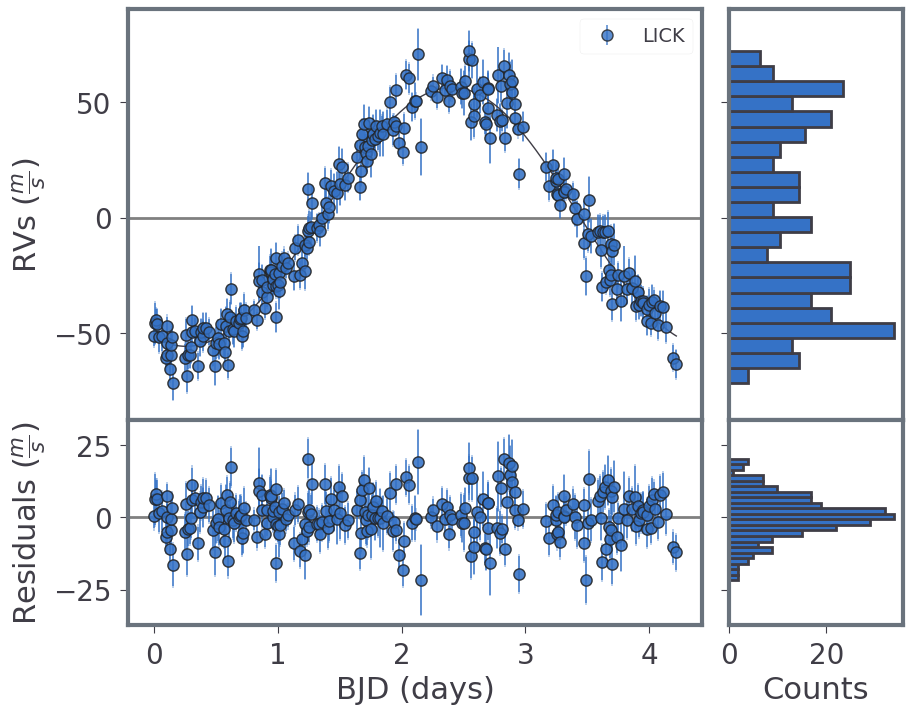

In [ ]:
from IPython.display import Image
loc = sim.saveplace

Image(filename=f'{loc}/plots/models/KeplerianBlock_1.png') 